# Wave Propagation Direction Analysis

This notebook detects propagating wave events in simulated local field potential (LFP) activity and estimates their propagation directions across a two-dimensional electrode array.

The analysis is used to characterize the directional distribution of waves generated by spatially structured spiking neural networks under different connectivity conditions.

## Configuration

The first cell defines the dataset and analysis parameters.

Select the dataset to analyze by setting DATASET = "fig5_g3.3", choosing from "fig5_g3.3", "fig5_g3.6", "S9_all", "S9_EtoI_EE", "S9_II", or "S9_all_I". Each option automatically loads the corresponding input directory, simulation IDs, number of recording chunks, and chunk duration.
 

## Method

The analysis proceeds as follows:

1. **Load LFP recordings.** Each simulation consists of consecutive `.mat` files containing LFP signals recorded across a square electrode array. Consecutive recording chunks are concatenated within each simulation, while independent simulations are analyzed separately.

2. **Filter the signals and extract instantaneous phase.** Each channel is standardized, and a common frequency band is selected around the dominant peak of the mean LFP power spectral density (PSD), unless a manual band is specified. Instantaneous phases are extracted using the Hilbert transform.

3. **Identify wave events.** At each time point, spatial phase gradients are calculated across the electrode array. Their directional coherence is quantified by the magnitude of the mean normalized phase-gradient vector, \(r(t)\). Consecutive frames exceeding the selected coherence threshold are grouped into candidate wave events, subject to a minimum-duration criterion.

4. **Estimate propagation direction.** A plane is fitted to the spatial phase distribution at each time point to estimate the phase-gradient vector \((k_x,k_y)\). The direction of propagation is determined from the phase gradient and the sign of the temporal phase derivative:

   \[
   \mathbf{d}(t)=-\operatorname{sign}\left(\frac{\partial\phi}{\partial t}\right)\frac{(k_x,k_y)}{\sqrt{k_x^2+k_y^2}}.
   \]

   A single propagation angle is assigned to each detected event using the circular mean of its valid frame-wise directions.

5. **Construct the direction distribution.** Event directions are pooled across simulations and represented in a polar histogram. Each event contributes one observation, independently of its duration.

Propagation angles are expressed in physical Cartesian coordinates, from 0° to 360°, measured counterclockwise: 0° corresponds to +x, 90° to +y, 180° to −x, and 270° to −y.
 


## Outputs

Results are saved to:

`DATA_DIR/wave_direction_analysis/`

The notebook generates:

- A polar histogram of wave propagation directions, saved as `.svg` and `.png`.
- A `.csv` file containing each detected event's simulation identifier, onset, duration, propagation angle, directional concentration, and fraction of frames with a valid direction estimate.
- A compressed `.npz` file containing event-level measurements and histogram data.
- A `.json` file recording analysis settings, input files, and detection metadata.

The notebook also provides diagnostic plots of the mean LFP power spectrum, channel-wise LFP traces, and spatial snapshots of individual detected events.

## Dependencies

Python 3, NumPy, SciPy, Matplotlib, and Jupyter Notebook.

In [1]:
from pathlib import Path
import re
import json
import csv
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import scipy.io as sio

# ------------------------------------------------------------
# Dataset configuration
# ------------------------------------------------------------

DATASET = "fig5_g3.3"

DATASETS = {
    # Figure 5
    "fig5_g3.3": {
        "directory": "results_f5_g3.3_rho0.6",
        "simulations": range(1, 3),
        "chunks": 5,
        "chunk_duration_ms": 1000.0,
    },
    "fig5_g3.6": {
        "directory": "results_f5_g3.6_rho0.6_nu0.92",
        "simulations": range(1, 20),
        "chunks": 5,
        "chunk_duration_ms": 500.0,
    },

    # Supplementary Figure S9
    "S9_all": {
        "directory": "Supplementary_results/nu_2000_all_0.6_g4.1",
        "simulations": range(1, 11),
        "chunks": 10,
        "chunk_duration_ms": 1000.0,
    },
    "S9_EtoI_EE": {
        "directory": "Supplementary_results/nu_2000_EI_EE_0.6_g4.1",
        "simulations": range(1, 11),
        "chunks": 10,
        "chunk_duration_ms": 1000.0,
    },
    "S9_II": {
        "directory": "Supplementary_results/nu_2000_II_0.6_g4.1",
        "simulations": range(1, 11),
        "chunks": 10,
        "chunk_duration_ms": 1000.0,
    },
    "S9_all_I": {
        "directory": "Supplementary_results/nu_2000_II_IE_0.6_g4.1",
        "simulations": range(1, 21),
        "chunks": 10,
        "chunk_duration_ms": 1000.0,
    },
}

# ------------------------------------------------------------
# Select dataset
# ------------------------------------------------------------
config = DATASETS[DATASET]

DATA_DIR = Path(config["directory"])
SIMULATION_IDS = list(config["simulations"])
EXPECTED_CHUNKS = config["chunks"]
CHUNK_DURATION_MS = config["chunk_duration_ms"]

MANUAL_BAND_HZ = None #None #[10, 45]  or None for the original PSD method
OUTPUT_DIR = DATA_DIR / "wave_direction_analysis"
LFP_SAMPLE_INTERVAL_MS = 1.0
ELECTRODE_SPACING_MM = 0.141
LFP_BAND_SEARCH_HZ = (5.0, 50.0)
LFP_BAND_LIMITS_HZ = (5.0, 30.0)
LFP_BAND_HALF_WIDTH_HZ = 3.0 #3.0
THRESHOLD_METHOD = "fixed"  # "fixed" or "statistical"
FIXED_R_THRESHOLD = 0.5  # use the same value as code A, or choose another cutoff
LFP_FILTER_ORDER = 4
MIN_WAVE_DURATION_MS = 1.0
MIN_GRADIENT_MM_INV = 1e-3  # original numerical direction floor
EDGE_EXCLUSION_MS = 0.0
N_DIRECTION_BINS = 14  # 15-degree bins, centred at 0°, 15°, ...
HISTOGRAM_NORMALIZATION = "probability"  # "probability" or "count"


In [2]:
def load_simulation(simulation_id):
    pattern = re.compile(r"LFP_i(\d+)_J" + str(simulation_id) + r"\.mat$")
    indexed = sorted((int(m.group(1)), p) for p in DATA_DIR.glob("LFP_i*_J*.mat")
                     if (m := pattern.fullmatch(p.name)))
    indices = [i for i, _ in indexed]
    if indices not in [list(range(EXPECTED_CHUNKS)), list(range(1, EXPECTED_CHUNKS + 1))]:
        raise ValueError(f"J{simulation_id}: expected chunks 0–{EXPECTED_CHUNKS-1} or "
                         f"1–{EXPECTED_CHUNKS}; found {indices} in {DATA_DIR.resolve()}")
    chunks = []
    for _, path in indexed:
        mat = sio.loadmat(path)
        if "data" not in mat:
            raise KeyError(f"{path}: missing data variable")
        chunk = np.asarray(mat["data"], dtype=float)
        if chunk.ndim != 2 or not np.all(np.isfinite(chunk)):
            raise ValueError(f"{path}: expected finite time × channel matrix")
        expected_samples = round(CHUNK_DURATION_MS / LFP_SAMPLE_INTERVAL_MS)

        if chunk.shape[0] != expected_samples:
            raise ValueError(
                f"{path}: expected {expected_samples} samples "
                f"({CHUNK_DURATION_MS} ms); got {chunk.shape}"
            )
        if chunks and chunk.shape[1] != chunks[0].shape[1]:
            raise ValueError("Channel count differs between chunks")
        chunks.append(chunk)
    lfp = np.concatenate(chunks, axis=0)
    std = lfp.std(axis=0, keepdims=True)
    if np.any(std == 0):
        raise ValueError(f"J{simulation_id}: constant LFP channel; check saved data")
    return (lfp-lfp.mean(axis=0, keepdims=True))/std, [str(p) for _, p in indexed]


def check_geometry(n_channels):
    side = grid_side(n_channels)
    if side < 2:
        raise ValueError("At least a 2 × 2 grid is required")
    idx = np.arange(n_channels)
    x = (idx // side - (side-1)/2) * ELECTRODE_SPACING_MM
    y = (idx % side - (side-1)/2) * ELECTRODE_SPACING_MM
    for name, expected in [("Rec_x.mat", x), ("Rec_y.mat", y)]:
        path = DATA_DIR / name
        if path.exists():
            actual = np.asarray(sio.loadmat(path)["data"], float).ravel()*1000
            if actual.shape != expected.shape or not np.allclose(actual, expected, atol=1e-6, rtol=1e-5):
                raise ValueError(f"{name}: coordinates disagree with declared geometry (expected metres)")
    return side


def phase_and_frequency(lfp, band_hz):
    fs = 1000 / LFP_SAMPLE_INTERVAL_MS
    side = grid_side(lfp.shape[1])
    sos = signal.butter(LFP_FILTER_ORDER, band_hz, btype="bandpass", fs=fs, output="sos")
    analytic = signal.hilbert(signal.sosfiltfilt(sos, lfp, axis=0), axis=0)
    raw = np.angle(analytic)
    # BEFORE subtracting a reference: spatial referencing removes common temporal rotation.
    temporal_derivative = np.gradient(np.unwrap(raw, axis=0), 1/fs, axis=0)
    omega = np.median(temporal_derivative, axis=1)  # robust common rotation, rad/s
    phases = raw.reshape(len(raw), side, side).transpose(0, 2, 1)
    phases = np.unwrap(np.unwrap(phases, axis=1), axis=2)
    phases -= phases[:, side//2, side//2][:, None, None]
    return phases.astype(np.float32), omega


In [3]:
def grid_side(n_channels):
    n_side = int(round(np.sqrt(n_channels)))
    if n_side * n_side != n_channels:
        raise ValueError(
            "The MATLAB channel map requires a square array, not {} channels."
            .format(n_channels)
        )
    return n_side

def condition_band(lfp_trials):
    """Choose the common LFP band from the mean PSD across trials/channels."""
    fs_hz = 1000.0 / LFP_SAMPLE_INTERVAL_MS
    nperseg = min(1000, min(lfp.shape[0] for lfp in lfp_trials.values()))
    if nperseg < 4:
        raise ValueError("LFP recordings are too short for spectral estimation.")

    mean_psd = None
    frequencies = None
    for lfp in lfp_trials.values():
        frequencies, psd = signal.welch(
            lfp,
            fs=fs_hz,
            nperseg=nperseg,
            noverlap=nperseg // 2,
            nfft=max(2048, nperseg),
            axis=0,
        )
        channel_mean_psd = psd.mean(axis=1)
        mean_psd = channel_mean_psd if mean_psd is None else mean_psd + channel_mean_psd
    mean_psd /= len(lfp_trials)

    search = (
        (frequencies >= LFP_BAND_SEARCH_HZ[0])
        & (frequencies <= LFP_BAND_SEARCH_HZ[1])
    )
    if not np.any(search):
        raise ValueError("No PSD frequencies lie in LFP_BAND_SEARCH_HZ.")
    dominant_hz = frequencies[search][np.argmax(mean_psd[search])]
    band = (
        max(LFP_BAND_LIMITS_HZ[0], dominant_hz - LFP_BAND_HALF_WIDTH_HZ),
        min(LFP_BAND_LIMITS_HZ[1], dominant_hz + LFP_BAND_HALF_WIDTH_HZ),)


    if not (0 < band[0] < band[1] < fs_hz / 2):
        raise ValueError("Invalid LFP band {} around {:.2f} Hz.".format(band, dominant_hz))
    return dominant_hz, band


def plane_design(n_side):
    x_mm, y_mm = np.meshgrid(
        np.arange(n_side) * ELECTRODE_SPACING_MM,
        np.arange(n_side) * ELECTRODE_SPACING_MM,
    )
    design = np.column_stack((
        x_mm.ravel(),
        y_mm.ravel(),
        np.ones(n_side**2)
    ))
    return np.linalg.pinv(design)


def phase_metrics(phases, pinv_design):
    """Compute spatial phase coherence r and plane-fit slopes kx, ky."""

    grad_y, grad_x = np.gradient(
        phases,
        ELECTRODE_SPACING_MM,
        ELECTRODE_SPACING_MM,
        axis=(1, 2),
        edge_order=1,
    )

    grad_norm = np.hypot(grad_x, grad_y)
    valid = grad_norm > MIN_GRADIENT_MM_INV
    n_valid = valid.sum(axis=(1, 2)).astype(float)

    unit_x = np.divide(
        grad_x, grad_norm,
        out=np.zeros_like(grad_x),
        where=valid,
    )
    unit_y = np.divide(
        grad_y, grad_norm,
        out=np.zeros_like(grad_y),
        where=valid,
    )

    mean_x = np.divide(
        unit_x.sum(axis=(1, 2)),
        n_valid,
        out=np.zeros_like(n_valid),
        where=n_valid > 0,
    )
    mean_y = np.divide(
        unit_y.sum(axis=(1, 2)),
        n_valid,
        out=np.zeros_like(n_valid),
        where=n_valid > 0,
    )

    spatial_r = np.hypot(mean_x, mean_y)

    phase_flat = phases.reshape(phases.shape[0], -1)
    coefficients = phase_flat @ pinv_design.T

    return spatial_r, coefficients[:, 0], coefficients[:, 1]



In [4]:
def event_directions(r, kx, ky, omega, eligible, r_cut, simulation_id):
 

    detected = (r > r_cut) & eligible
    changes = np.flatnonzero(np.diff(np.r_[False, detected, False].astype(int)))
    minimum = max(1, int(np.ceil(
        MIN_WAVE_DURATION_MS / LFP_SAMPLE_INTERVAL_MS
    )))
    records = []

    for start, stop in zip(changes[::2], changes[1::2]):
        if stop - start < minimum:
            continue

        a, b, w = kx[start:stop], ky[start:stop], omega[start:stop]
        k = np.hypot(a, b)
        valid = (
            np.isfinite(k) & (k > MIN_GRADIENT_MM_INV)
            & np.isfinite(w) & (w != 0)
        )
        angle = resultant = np.nan

        if valid.any():
            ux = -np.sign(w[valid]) * a[valid] / k[valid]
            uy = -np.sign(w[valid]) * b[valid] / k[valid]
            resultant = float(np.hypot(ux.mean(), uy.mean()))
            if resultant > np.finfo(float).eps:
                angle = float(np.arctan2(uy.mean(), ux.mean()) % (2 * np.pi))

        records.append(dict(
            simulation_id=simulation_id,
            start_frame=int(start),
            stop_frame_exclusive=int(stop),
            start_ms=start * LFP_SAMPLE_INTERVAL_MS,
            duration_ms=(stop - start) * LFP_SAMPLE_INTERVAL_MS,
            direction_rad=angle,
            direction_deg=np.degrees(angle),
            direction_resultant=resultant,
            valid_direction_fraction=float(valid.mean()),
        ))

    return records

def analyse_simulations(lfp_by_simulation):

    counts = {lfp.shape[1] for lfp in lfp_by_simulation.values()}
    if len(counts) != 1:
        raise ValueError("Simulations have different channel counts")

    n_channels = next(iter(counts))
    side = check_geometry(n_channels)

    if MANUAL_BAND_HZ is None:
        peak, band = condition_band(lfp_by_simulation)
    else:
        peak, band = np.nan, tuple(MANUAL_BAND_HZ)

    if not (0 < band[0] < band[1] < 500 / LFP_SAMPLE_INTERVAL_MS):
        raise ValueError(f"Invalid filter band {band}")

    pinv = plane_design(side)
    r_cut = FIXED_R_THRESHOLD
    frames = {}

    edge = int(np.ceil(EDGE_EXCLUSION_MS / LFP_SAMPLE_INTERVAL_MS))
    if edge < 0:
        raise ValueError("EDGE_EXCLUSION_MS must be nonnegative")

    for sim, lfp in lfp_by_simulation.items():
        if 2 * edge >= len(lfp):
            raise ValueError("Edge exclusion leaves no data")

        phases, omega = phase_and_frequency(lfp, band)
        r, kx, ky = phase_metrics(phases, pinv)

        eligible = np.zeros(len(lfp), dtype=bool)
        eligible[edge:len(lfp) - edge] = True

        frames[sim] = (r, kx, ky, omega, eligible)

    events = []

    for sim, frame_data in frames.items():
        records = event_directions(
            *frame_data, r_cut, sim
        )
        events.extend(records)

        n_valid = sum(
            np.isfinite(event["direction_rad"])
            for event in records
        )

        print(
            f"J{sim}: {len(records)} events, "
            f"{n_valid} with a defined direction"
        )

    print(
        f"Band: {band} Hz; PSD peak: {peak:.3f} Hz; "
        f"r > {r_cut:.6g}"
    )

    return events, dict(
        band_hz=list(band),
        dominant_frequency_hz=float(peak),
        r_threshold=float(r_cut),
    )

In [5]:
lfp_by_simulation, source_files = {}, {}
for sim in SIMULATION_IDS:
    lfp_by_simulation[sim], source_files[str(sim)] = load_simulation(sim)
events, analysis_metadata = analyse_simulations(lfp_by_simulation)
angles = np.array([e["direction_rad"] for e in events], dtype=float)
angles = angles[np.isfinite(angles)]


J1: 20 events, 20 with a defined direction
J2: 21 events, 21 with a defined direction
Band: (np.float64(17.5078125), np.float64(23.5078125)) Hz; PSD peak: 20.508 Hz; r > 0.5; residual < 0.2 rad


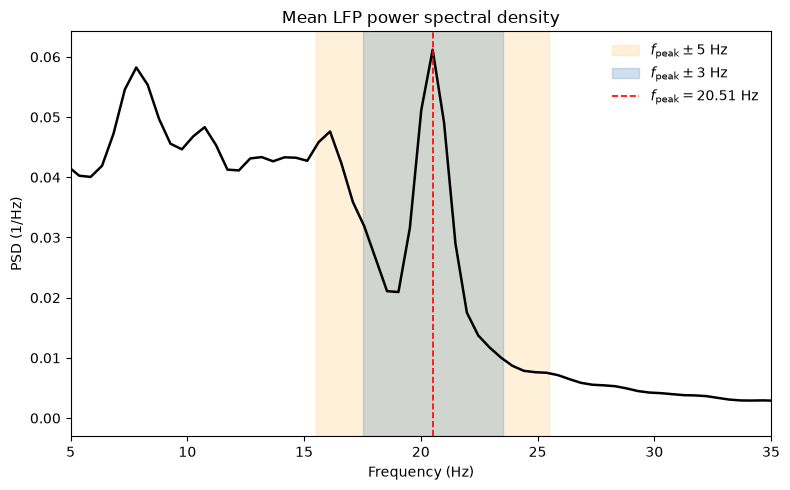

PSD peak: 20.51 Hz


In [6]:

# ------------------------------------------------------------
# Mean LFP PSD across simulations and channels
# Same Welch settings as condition_band()
# ------------------------------------------------------------

fs_hz = 1000.0 / LFP_SAMPLE_INTERVAL_MS
nperseg = min(
    1000,
    min(lfp.shape[0] for lfp in lfp_by_simulation.values())
)

psd_all = []

for sim, lfp in lfp_by_simulation.items():
    frequencies, psd = signal.welch(
        lfp,
        fs=fs_hz,
        nperseg=nperseg,
        noverlap=nperseg // 2,
        nfft=max(2048, nperseg),
        axis=0
    )
    psd_all.append(psd.mean(axis=1))

mean_psd = np.mean(psd_all, axis=0)

# Find dominant frequency (same search range as detector)
search = (
    (frequencies >= LFP_BAND_SEARCH_HZ[0]) &
    (frequencies <= LFP_BAND_SEARCH_HZ[1])
)

f_peak = frequencies[search][np.argmax(mean_psd[search])]

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(frequencies, mean_psd, color='black', lw=1.8)

# Wider band ±5 Hz
ax.axvspan(
    f_peak - 5, f_peak + 5,
    color='orange', alpha=0.15,
    label=r'$f_{\mathrm{peak}}\pm5$ Hz'
)

# Original band ±3 Hz
ax.axvspan(
    f_peak - 3, f_peak + 3,
    color='steelblue', alpha=0.25,
    label=r'$f_{\mathrm{peak}}\pm3$ Hz'
)

ax.axvline(
    f_peak, color='red', ls='--', lw=1.2,
    label=fr'$f_{{\mathrm{{peak}}}}={f_peak:.2f}$ Hz'
)

ax.set_xlim(5, 35)
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('PSD (1/Hz)')
ax.set_title('Mean LFP power spectral density')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

print(f"PSD peak: {f_peak:.2f} Hz")


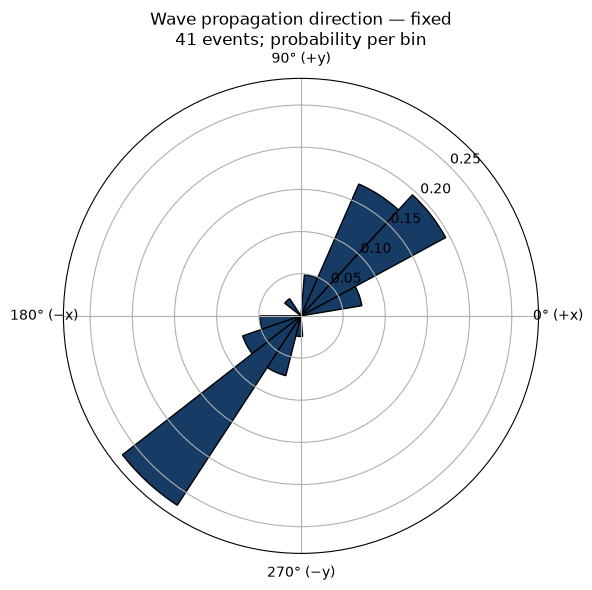

Saved histogram, event table, arrays and settings to /Users/ludovica/Documents/Documents_MAC/Duke/Brian_simulations/Paper_figures_simulations/GitHub_clean/simulations/results_f5/results_f5_g3.3_rho0.6/wave_direction_analysis


In [7]:
N_DIRECTION_BINS=19


if HISTOGRAM_NORMALIZATION not in ("probability", "count"):
    raise ValueError("HISTOGRAM_NORMALIZATION must be probability or count")
if not isinstance(N_DIRECTION_BINS, int) or N_DIRECTION_BINS < 3:
    raise ValueError("N_DIRECTION_BINS must be an integer >= 3")
width = 2*np.pi/N_DIRECTION_BINS
edges = np.arange(N_DIRECTION_BINS+1)*width - width/2
wrapped_angles = (angles + width/2) % (2*np.pi) - width/2
counts, _ = np.histogram(wrapped_angles, bins=edges)
heights = counts.astype(float)
if HISTOGRAM_NORMALIZATION == "probability" and len(angles):
    heights /= len(angles)
fig, ax = plt.subplots(figsize=(6, 6), subplot_kw={"projection": "polar"})
ax.bar(edges[:-1]+width/2, heights, width=width, color="#163B65", edgecolor="black")
ax.set_theta_zero_location("E")
ax.set_theta_direction(1)
ax.set_thetagrids([0, 90, 180, 270], ["0° (+x)", "90° (+y)", "180° (−x)", "270° (−y)"])
ax.set_title(
    f"Wave propagation direction\n"
    f"{len(angles)} events; {HISTOGRAM_NORMALIZATION} per bin",
    pad=24,
)
if not len(angles):
    ax.text(0.5, 0.5, "No events with defined direction", ha="center", transform=ax.transAxes)
ax.set_rlabel_position(45)
fig.tight_layout()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
stem = "wave detection fixed"
fig.savefig(OUTPUT_DIR / f"{stem}.svg", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / f"{stem}.png", dpi=300, bbox_inches="tight")
plt.show()

fields = ["simulation_id", "start_frame", "stop_frame_exclusive", "start_ms", "duration_ms",
          "direction_rad", "direction_deg", "direction_resultant", "valid_direction_fraction"]
with (OUTPUT_DIR / f"{stem}_events.csv").open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=fields)
    writer.writeheader()
    writer.writerows(events)
np.savez_compressed(OUTPUT_DIR / f"{stem}.npz",
                    **{key: np.array([e[key] for e in events]) for key in fields},
                    histogram_counts=counts, histogram_edges_rad=edges)
settings = {key: value for key, value in list(globals().items())
            if key.isupper() and isinstance(value, (str, int, float, list, tuple, Path, type(None)))}
metadata = dict(settings=settings, source_files=source_files, analysis=analysis_metadata,
                detected_events=len(events), histogram_events=len(angles),
                histogram_weighting="one circular-mean direction per event, pooled simulations")
(OUTPUT_DIR / f"{stem}_settings.json").write_text(json.dumps(metadata, indent=2, default=str))
print(f"Saved histogram, event table, arrays and settings to {OUTPUT_DIR.resolve()}")


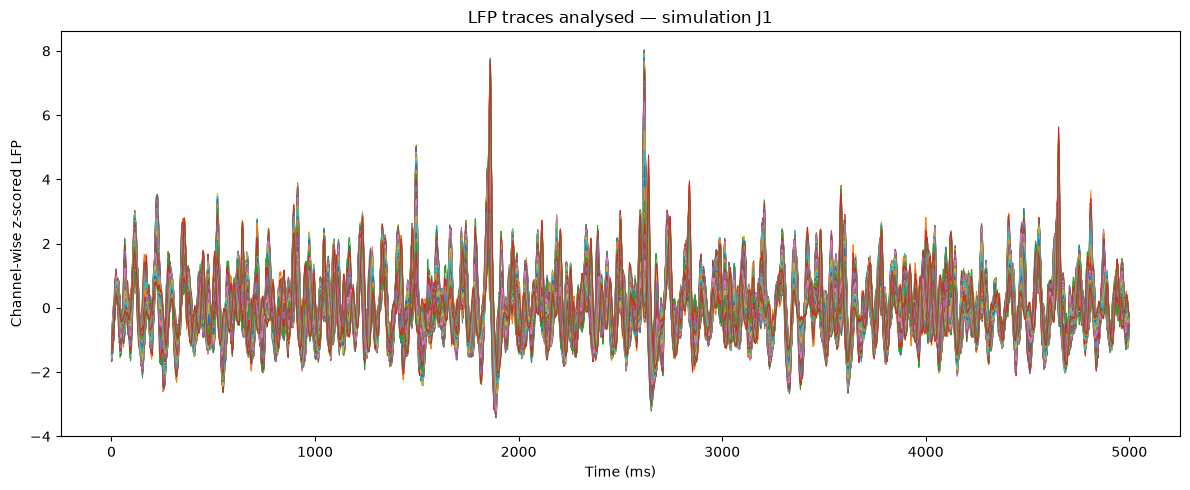

In [8]:


sim =1

lfp = lfp_by_simulation[sim]
time_ms = np.arange(lfp.shape[0]) * LFP_SAMPLE_INTERVAL_MS

plt.figure(figsize=(12, 5))
plt.plot(time_ms, lfp, linewidth=0.7)
plt.xlabel("Time (ms)")
plt.ylabel("Channel-wise z-scored LFP")
plt.title(f"LFP traces analysed — simulation J{sim}")
plt.tight_layout()
plt.show()

  0: J1 | start 65.0 ms | duration 173.0 ms | direction 210.9°
  1: J1 | start 278.0 ms | duration 150.0 ms | direction 51.5°
  2: J1 | start 460.0 ms | duration 231.0 ms | direction 226.1°
  3: J1 | start 1124.0 ms | duration 207.0 ms | direction 51.9°
  4: J1 | start 1385.0 ms | duration 199.0 ms | direction 230.6°
  5: J1 | start 1737.0 ms | duration 273.0 ms | direction 44.3°
  6: J1 | start 2136.0 ms | duration 359.0 ms | direction 50.6°
  7: J1 | start 2546.0 ms | duration 12.0 ms | direction 220.4°
  8: J1 | start 2602.0 ms | duration 291.0 ms | direction 48.8°
  9: J1 | start 3058.0 ms | duration 334.0 ms | direction 219.3°
 10: J1 | start 3514.0 ms | duration 181.0 ms | direction 220.9°
 11: J1 | start 3735.0 ms | duration 125.0 ms | direction 36.5°
 12: J1 | start 4039.0 ms | duration 201.0 ms | direction 205.3°
 13: J1 | start 4352.0 ms | duration 27.0 ms | direction 227.7°
 14: J1 | start 4530.0 ms | duration 156.0 ms | direction 37.1°
 15: J1 | start 4735.0 ms | duration 2

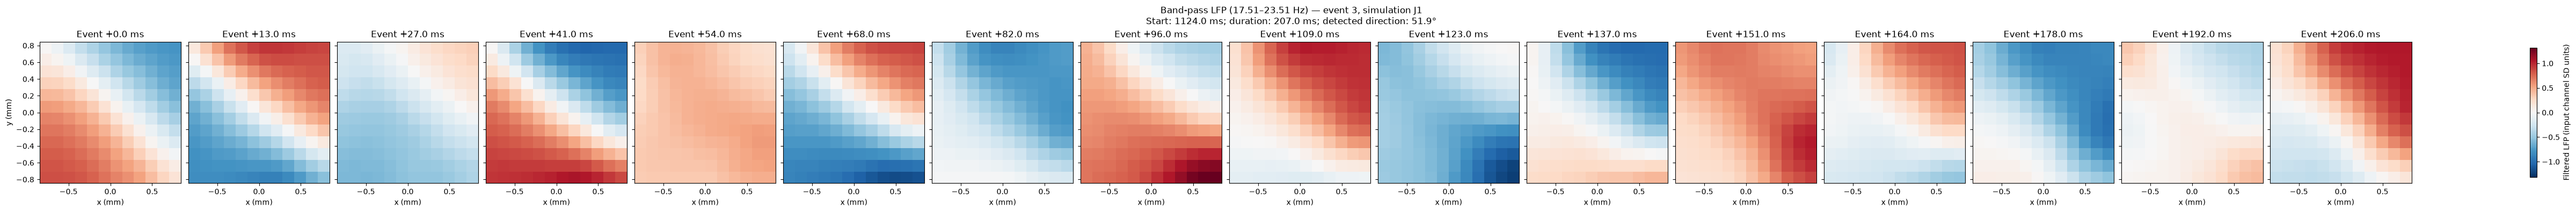

In [9]:
# Select an event from the existing event list.
EVENT_INDEX = 3
N_SNAPSHOTS = 16
SHOW_FILTERED = True  # False: unfiltered, channel-wise standardized LFP

if not events:
    raise ValueError("No detected events to plot.")

# Preview event indices to help choose an event.
for idx, ev in enumerate(events[:20]):
    print(
        f"{idx:3d}: J{ev['simulation_id']} | "
        f"start {ev['start_ms']:.1f} ms | "
        f"duration {ev['duration_ms']:.1f} ms | "
        f"direction {ev['direction_deg']:.1f}°"
    )

event = events[EVENT_INDEX]
sim_id = event["simulation_id"]
start = event["start_frame"]
stop = event["stop_frame_exclusive"]

lfp = lfp_by_simulation[sim_id]
side = check_geometry(lfp.shape[1])
band = tuple(analysis_metadata["band_hz"])
fs_hz = 1000.0 / LFP_SAMPLE_INTERVAL_MS

if SHOW_FILTERED:
    # Same filter as phase_and_frequency(); filter before cropping.
    sos = signal.butter(
        LFP_FILTER_ORDER,
        band,
        btype="bandpass",
        fs=fs_hz,
        output="sos",
    )
    displayed_lfp = signal.sosfiltfilt(sos, lfp, axis=0)
    display_label = f"Band-pass LFP ({band[0]:.2f}–{band[1]:.2f} Hz)"
    colorbar_label = "Filtered LFP (input channel SD units)"
else:
    displayed_lfp = lfp
    display_label = "Unfiltered LFP"
    colorbar_label = "Channel-wise standardized LFP"

# Channel index increases in +y first, then +x.
# Result: maps[time, y, x].
event_maps = (
    displayed_lfp[start:stop]
    .reshape(stop - start, side, side)
    .transpose(0, 2, 1)
)

# Equally spaced snapshots within the detected event.
snapshot_indices = np.unique(
    np.linspace(
        0, len(event_maps) - 1,
        min(N_SNAPSHOTS, len(event_maps)),
        dtype=int,
    )
)

# Pixel edges centred on the physical electrode coordinates.
half_extent = side * ELECTRODE_SPACING_MM / 2
extent = [-half_extent, half_extent, -half_extent, half_extent]

# One symmetric colour scale for the entire event.
vmax = float(np.max(np.abs(event_maps)))
if vmax == 0:
    vmax = 1.0

fig, axes = plt.subplots(
    1, len(snapshot_indices),
    figsize=(3.0 * len(snapshot_indices), 3.8),
    sharex=True,
    sharey=True,
    squeeze=False,
    constrained_layout=True,
)

for ax, local_frame in zip(axes.ravel(), snapshot_indices):
    image = ax.imshow(
        event_maps[local_frame],
        origin="lower",
        extent=extent,
        cmap="RdBu_r",
        vmin=-vmax,
        vmax=vmax,
        interpolation="nearest",
        aspect="equal",
    )
    relative_ms = local_frame * LFP_SAMPLE_INTERVAL_MS
    ax.set_title(f"Event +{relative_ms:.1f} ms")
    ax.set_xlabel("x (mm)")

axes[0, 0].set_ylabel("y (mm)")
fig.colorbar(
    image, ax=axes.ravel().tolist(),
    label=colorbar_label, shrink=0.8,
)

fig.suptitle(
    f"{display_label} — event {EVENT_INDEX}, simulation J{sim_id}\n"
    f"Start: {event['start_ms']:.1f} ms; "
    f"duration: {event['duration_ms']:.1f} ms; "
    f"detected direction: {event['direction_deg']:.1f}°"
)

plt.show()